# Malaria Cell Image Classification | Computer Vision with PyTorch

## Tech Stack
Python, PyTorch, Torchvision, Pandas, Matplotlib, Seaborn, Scikit-learn, PIL.

## Project Overview

This project focuses on developing a computer vision model for the automated classification of microscopic blood cell images to detect malaria infection.

The task is to distinguish between two classes:

*   Parasitized – red blood cells infected with malaria parasites.
*   Uninfected – healthy red blood cells.

The project uses Transfer Learning with the pre-trained SqueezeNet 1.0 architecture, adapted for binary image classification.

This Jupyter Notebook was developed based on materials from the webinar hosted by the Advanced Engineering School of Novosibirsk State University (NSU): “Practical Computer Vision Tools for Efficient Analysis of Biological Images.”

In [1]:
!pip3 install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu124 -q
!pip3 install kagglehub -q

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("miracle9to9/files1")

print("Path to dataset files:", path)

100%|██████████| 525M/525M [00:06<00:00, 81.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/miracle9to9/files1/versions/1


In [3]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from PIL import Image
import time

In [4]:
device_count = torch.cuda.device_count()
print(f"Available GPUs: {device_count}")

Available GPUs: 0


# Dataset

In [5]:
#Dataset structure
base_dir = "/root/.cache/kagglehub/datasets/miracle9to9/files1/versions/1"

for root, dirs, files in os.walk(base_dir):
    level = root.replace(base_dir, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")
    if level >= 3:
        continue

1/
    Malaria Cells/
        single_prediction/
        training_set/
            Parasitized/
            Uninfected/
        testing_set/
            Parasitized/
            Uninfected/


In [6]:
#base_dir = 'Malaria Cells'
base_dir = "/root/.cache/kagglehub/datasets/miracle9to9/files1/versions/1/Malaria Cells"
def create_dataframe(base_dir):
    data = []
    for split in ['training_set', 'testing_set']:
        split_dir = os.path.join(base_dir, split)
        for label_name in ['Parasitized', 'Uninfected']:
            folder_path = os.path.join(split_dir, label_name)
            if label_name == 'Parasitized':
                label = 1
            else:
                label = 0

            for img_name in os.listdir(folder_path):
                img_path = os.path.join(folder_path, img_name)
                data.append({
                    'filepath': img_path,
                    'label': label,
                    'split': 'train' if split == 'training_set' else 'test'
                            })

    df = pd.DataFrame(data)
    print(f"Total number of images: {len(df)}")
    print(f"train: {len(df[df['split'] == 'train'])}, test: {len(df[df['split'] == 'test'])}")
    return df

df = create_dataframe(base_dir)

Total number of images: 43392
train: 27560, test: 15832


In [7]:
df = df[~df['filepath'].str.endswith('Thumbs.db', na=False)].reset_index(drop=True)
df

,filepath,label,split
0,/root/.cache/kagglehub/datasets/miracle9to9/fi...,1,train
1,/root/.cache/kagglehub/datasets/miracle9to9/fi...,1,train
2,/root/.cache/kagglehub/datasets/miracle9to9/fi...,1,train
3,/root/.cache/kagglehub/datasets/miracle9to9/fi...,1,train
4,/root/.cache/kagglehub/datasets/miracle9to9/fi...,1,train
...,...,...,...
43385,/root/.cache/kagglehub/datasets/miracle9to9/fi...,0,test
43386,/root/.cache/kagglehub/datasets/miracle9to9/fi...,0,test
43387,/root/.cache/kagglehub/datasets/miracle9to9/fi...,0,test
43388,/root/.cache/kagglehub/datasets/miracle9to9/fi...,0,test


In [8]:
class MalariaDataset(Dataset):
    def __init__(self, dataframe, transform = None):
        self.dataframe = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx]['filepath']
        label = self.dataframe.iloc[idx]['label']
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label

In [9]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    # Normalization for ImageNet
    transforms.Normalize(mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225])
])

In [10]:
# Let’s take just 10% of the data
full_train_df = df[df['split'] == 'train'].reset_index(drop=True)
full_test_df = df[df['split'] == 'test'].reset_index(drop=True)

train_df, _ = train_test_split(full_train_df, train_size=0.1, \
                               stratify=full_train_df['label'], random_state=42)
test_df, _ = train_test_split(full_test_df, train_size=0.1, \
                               stratify=full_test_df['label'], random_state=42)

print(f"Full train: {len(full_train_df)}, 10%: {len(train_df)}")
print(f"Full test: {len(full_test_df)}, 10%: {len(test_df)}")
print("\nClass balance in train 10%:")
print(train_df['label'].value_counts(normalize=True))

train_dataset = MalariaDataset(train_df, transform=train_transform)
test_dataset = MalariaDataset(test_df, transform=test_transform)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, drop_last=True)

Full train: 27558, 10%: 2755
Full test: 15832, 10%: 1583

Class balance in train 10%:
label
1    0.500181
0    0.499819
Name: proportion, dtype: float64


# https://pytorch.org/vision/stable/models.html - get pretrained image classification model

In [14]:
from torchvision.models import squeezenet1_0

In [15]:
model = squeezenet1_0(pretrained=True)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=SqueezeNet1_0_Weights.IMAGENET1K_V1`. You can also use `weights=SqueezeNet1_0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/squeezenet1_0-b66bff10.pth" to /root/.cache/torch/hub/checkpoints/squeezenet1_0-b66bff10.pth


100%|██████████| 4.78M/4.78M [00:00<00:00, 27.0MB/s]


In [27]:
model.classifier[1] = nn.Conv2d(512, 2, kernel_size=(1, 1), stride=(1, 1))

for param in model.features.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

# Model training

In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device in use: {device}")
model = model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)

train_losses = []
test_losses = []
num_epochs = 5

for epoch in range(num_epochs):
    train_loss = 0.0
    for batch, labels in train_loader:
        batch, labels = batch.to(device), labels.to(device)
        model.train()
        optimizer.zero_grad()
        outputs = model(batch.float())
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    print(f'Epoch [{epoch+1}/{num_epochs}], Average train loss = {train_loss / len(train_loader):.4f}')

    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        for batch, labels in test_loader:
            batch, labels = batch.to(device), labels.to(device)
            outputs = model(batch.float())
            loss = criterion(outputs, labels)
            test_loss += loss.item()
    print(f'Average test loss = {test_loss / len(test_loader):.4f}')

    train_losses.append(train_loss / len(train_loader))
    test_losses.append(test_loss / len(test_loader))

print('Training is finished')

torch.save(model, 'Malaria_squeezenet.pth')

combined_list = list(zip(train_losses, test_losses))
losses = pd.DataFrame(combined_list, columns=['train_loss', 'test_loss'])
losses.to_csv('squeezenet_losses.csv', index=False)

Device in use: cpu
Epoch [1/5], Average train loss = 0.3562
Average test loss = 0.2442
Epoch [2/5], Average train loss = 0.2235
Average test loss = 0.2150
Epoch [3/5], Average train loss = 0.1988
Average test loss = 0.2504
Epoch [4/5], Average train loss = 0.1864
Average test loss = 0.1834
Epoch [5/5], Average train loss = 0.1704
Average test loss = 0.1815
Training is finished


Visualisation of the training

<Axes: >

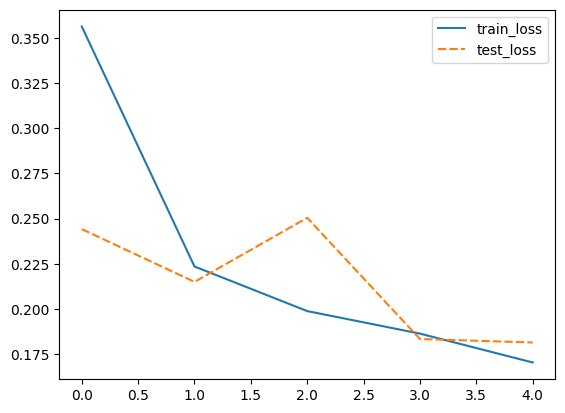

In [23]:
losses = pd.read_csv('squeezenet_losses.csv')
sns.lineplot(data=losses)

# Testing on individual images

In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

loaded_obj = torch.load('Malaria_squeezenet.pth', weights_only=False)


In [25]:
def predict_single_image(image_path, model, device):
    model.eval()

    image = Image.open(image_path).convert('RGB')
    image = test_transform(image).unsqueeze(0)

    with torch.no_grad():
        image = image.to(device)
        outputs = model(image)
        _, preds = torch.max(outputs, 1)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]

    class_names = ['Uninfected', 'Parasitized']
    pred_class = class_names[preds[0]]
    confidence = probabilities[preds[0]].item() * 100

    print(f"Image: {os.path.basename(image_path)}")
    print(f"Prediction: {pred_class}")
    print(f"Confidence: {confidence:.2f}%\n")

model.eval()

single_pred_dir = os.path.join(base_dir, 'single_prediction')
if os.path.exists(single_pred_dir):
    print("Single predictions")
    for img_name in os.listdir(single_pred_dir):
        img_path = os.path.join(single_pred_dir, img_name)
        predict_single_image(img_path, model, device)

Single predictions
Image: Parasitised.png
Prediction: Parasitized
Confidence: 99.99%

Image: Uninfected.png
Prediction: Uninfected
Confidence: 96.65%



Images found for verification: 2


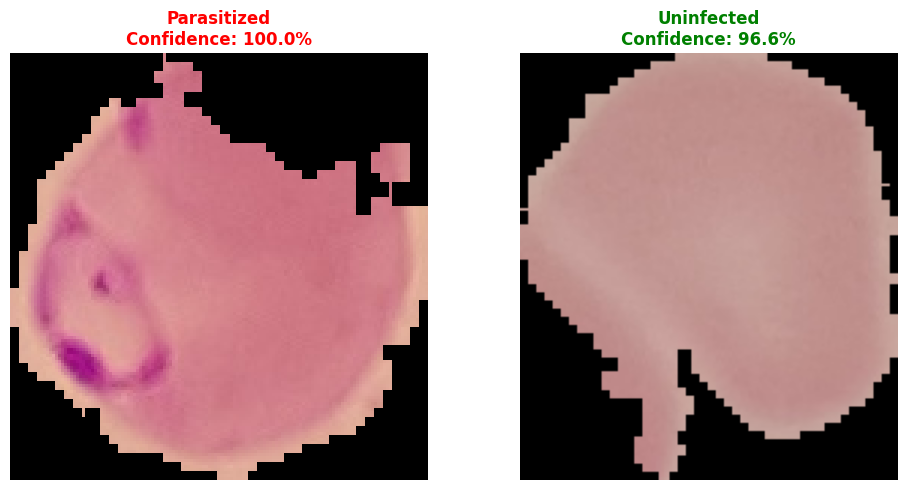

In [26]:
model.eval()

single_pred_dir = os.path.join(base_dir, 'single_prediction')
valid_extensions = {'.jpg', '.jpeg', '.png', '.bmp'}
image_files = [
    f for f in os.listdir(single_pred_dir)
    if os.path.splitext(f)[1].lower() in valid_extensions
]

if not image_files:
    print(f"No images for prediction were found in the {single_pred_dir} folder.")
else:
    print(f"Images found for verification: {len(image_files)}")
    fig, axes = plt.subplots(1, len(image_files), figsize=(5 * len(image_files), 5))
    if len(image_files) == 1:
        axes = [axes]
    class_names = ['Uninfected', 'Parasitized']
    for i, img_name in enumerate(image_files):
        img_path = os.path.join(single_pred_dir, img_name)
        image_pil = Image.open(img_path).convert('RGB')
        image_tensor = test_transform(image_pil).unsqueeze(0).to(device)
        with torch.no_grad():
            outputs = model(image_tensor)
            probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
            pred_idx = torch.argmax(probabilities).item()
            confidence = probabilities[pred_idx].item() * 100

        pred_class = class_names[pred_idx]
        axes[i].imshow(image_pil)
        title_color = 'green' if pred_idx == 0 else 'red'

        axes[i].set_title(
            f"{pred_class}\nConfidence: {confidence:.1f}%",
            color=title_color,
            fontsize=12,
            fontweight='bold'
        )
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()